# 03 — Training Random Forest, SVM and Decision Tree
**MSc AI dissertation · Ghanem Almarar · Phase 3**

Implementation: [`src/models.py`](../src/models.py). This notebook explains *what* was done and *why*, and
displays the saved outputs. Training is launched with `python -m src.models` (≈ 30 min, dominated by the SVM);
the last cell can re-run it if you set `RETRAIN = True`.

**The one rule of this phase:** all three models get *identical* inputs (the SMOTE-balanced 80 % of KDDTrain+,
Min-Max scaled, top-20 RF-selected features) and *fixed, pre-declared* hyper-parameters. We are not tuning —
we are measuring how the algorithms themselves differ under the same conditions.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import models as M
T = ROOT/"results"/"tables"

## The three classifiers and their fixed settings
| Model | Idea (plain English) | Fixed hyper-parameters |
|---|---|---|
| **Random Forest** | 100 decision trees, each trained on a random bootstrap sample and a random subset of features; majority vote. Averaging many noisy trees cancels their individual mistakes → robust, hard to overfit. | `n_estimators=100, random_state=42` |
| **SVM (RBF kernel)** | Finds the boundary that leaves the widest margin between classes; the RBF kernel lets that boundary curve. Distance-based → this is why Min-Max scaling mattered. | `kernel='rbf', C=1.0, gamma='scale'` |
| **Decision Tree** | A single tree of yes/no questions on feature thresholds. Fully interpretable, very fast, but prone to overfitting → our baseline. | `criterion='gini', random_state=42` |

Everything not listed is the scikit-learn default and is recorded in `results/tables/training_run_log.json`.

In [2]:
log = json.loads((T/"training_run_log.json").read_text())
print("sklearn", log["sklearn_version"], "| python", log["python"], "| cpu", log["processor"])
pd.DataFrame({k: pd.Series(v) for k, v in log["hyperparameters"].items()}).fillna("")

sklearn 1.9.0 | python 3.14.5 | cpu Intel64 Family 6 Model 183 Stepping 1, GenuineIntel


,random_forest,svm_rbf,decision_tree
C,,1.0,
bootstrap,True,,
break_ties,,False,
cache_size,,200,
ccp_alpha,0.0,,0.0
class_weight,,,
coef0,,0.0,
criterion,gini,,gini
decision_function_shape,,ovr,
degree,,3,


## 10-fold stratified cross-validation
`StratifiedKFold(n_splits=10, shuffle=True, random_state=42)` splits the 269,370 balanced training rows into 10
equal parts, keeping class proportions; each model is trained on 9 parts and scored on the 10th, ten times.
The **mean ± std** across folds tells us both how good and how *stable* each model is. Scores are accuracy and
weighted precision / recall / F1 — the proposal's metrics (FPR is computed in Phase 4 on the true test sets,
where "Normal" is real, not synthetic).

In [3]:
cv = pd.read_csv(T/"cv_results_per_fold.csv")
summ = (cv.groupby("model")[["test_accuracy","test_precision_weighted","test_recall_weighted","test_f1_weighted","fit_time","score_time"]]
          .agg(["mean","std"]).round(4))
summ

test_accuracy         test_precision_weighted          \
                       mean     std                    mean     std   
model                                                                 
decision_tree        0.9955  0.0005                  0.9955  0.0005   
random_forest        0.9970  0.0003                  0.9970  0.0003   
svm_rbf              0.9556  0.0013                  0.9561  0.0013   

              test_recall_weighted         test_f1_weighted          fit_time  \
                              mean     std             mean     std      mean   
model                                                                           
decision_tree               0.9955  0.0005           0.9955  0.0005    1.3553   
random_forest               0.9970  0.0003           0.9970  0.0003   24.0512   
svm_rbf                     0.9556  0.0013           0.9555  0.0013  596.7495   

                       score_time           
                   std       mean      std  
model                                       
decision_tree   0.0395     0.0110   0.0024  
random_forest   0.2445     0.2171   0.0333  
svm_rbf        58.2028    68.7401  13.8069

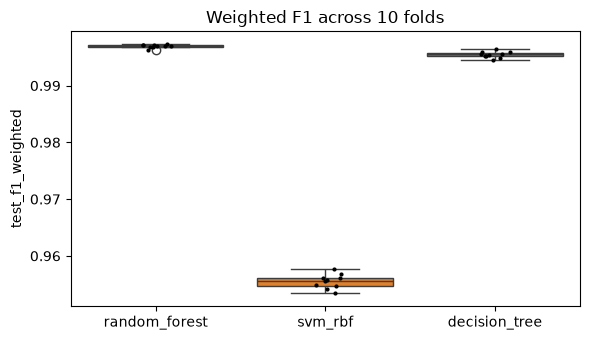

In [4]:
fig, ax = plt.subplots(figsize=(6,3.5))
sns.boxplot(data=cv, x="model", y="test_f1_weighted", hue="model", legend=False, ax=ax)
sns.stripplot(data=cv, x="model", y="test_f1_weighted", color="k", size=3, ax=ax)
ax.set_title("Weighted F1 across 10 folds"); ax.set_xlabel(""); plt.tight_layout(); plt.show()

## Final fit + timing (RQ2 — computational efficiency)
After CV, each model is fitted once on the full training set and timed, then timed again predicting the
25,195-row holdout and the 22,544-row KDDTest+. Same machine, same data → the times are directly comparable.

In [5]:
timing = pd.read_csv(T/"timing.csv"); timing

,model,fit_seconds,predict_holdout_seconds,predict_official_seconds,n_train,n_holdout,n_official,predict_holdout_us_per_row
0,random_forest,2.249,0.039,0.039,269370,25195,22544,1.54
1,svm_rbf,111.991,40.627,36.442,269370,25195,22544,1612.49
2,decision_tree,0.864,0.002,0.001,269370,25195,22544,0.08


## What to carry into the dissertation
* **Ch3** — the table of fixed hyper-parameters above + the CV protocol paragraph.
* **Ch4** — Table: CV mean ± std per model; Table: fit/predict times; Figure: CV F1 box-plot.
* **Ch5 (RQ2)** — predict time per row is the deployment-relevant number: an IDS scores traffic continuously.

In [6]:
RETRAIN = False      # set True to re-run the full ~30 min training from this notebook
if RETRAIN:
    M.run()